# Física acoplada: una reacción exotérmica con transferencia de calor

**FEM-sim · cuaderno de ejemplo paso a paso**

Este cuaderno monta, resuelve e interpreta un problema en el que **dos físicas se resuelven juntas**: el transporte de
especies químicas y la conducción de calor. Una reacción química libera calor, y la temperatura que resulta cambia la
velocidad de esa misma reacción. Es un lazo de retroalimentación que no se puede estudiar resolviendo cada física por separado.

**Qué vas a encontrar**

| # | Sección | Qué responde |
|---|---|---|
| 1 | El problema físico | ¿Qué ecuaciones y condiciones se resuelven y cómo se acoplan? |
| 2 | Preparación | ¿Qué módulos se usan y para qué sirve cada uno? |
| 3 | Parámetros | ¿Qué significan los números del modelo? |
| 4 | La malla | ¿Cómo se discretiza la placa y cómo se seleccionan los bordes? |
| 5 | El modelo con dos físicas | ¿Qué hace `Model(psc=[ht, mt])` por dentro? |
| 6 | La reacción | ¿Cómo se declara y cómo se calcula su velocidad y su derivada? |
| 7 | Condiciones de contorno e iniciales | ¿Qué convención de signos se usa y dónde se guarda cada condición? |
| 8 | Configuración del solver | ¿Qué significa cada opción? |
| 9 | Qué ocurre dentro de la simulación | Geometría, grados de libertad, matrices, jacobiano y Newton |
| 10 | Resolver y mostrar los resultados | Campos, perfiles y balance de energía |
| 11 | Retroalimentación térmica | ¿Cuánto importa el acoplamiento? |
| 12 | Verificación | ¿Cómo sabemos que el resultado es correcto? |
| 13 | Arranque transitorio | ¿Cómo evoluciona el reactor en el tiempo? |
| 14 | Presentación y resumen | Ideas clave y cómo seguir |

> **Requisitos.** Ejecuta el cuaderno desde la raíz del proyecto, con el entorno `.venv` (ver `requirements.txt`).
> Todo el cuaderno tarda menos de un minuto en ejecutarse.

## 1. El problema físico

Una placa porosa de $1 \times 0.5$ (unidades adimensionales) recibe un reactivo **A** por su borde izquierdo. Dentro de la placa
**A** se transforma en el producto **C** mediante una reacción de primer orden y **exotérmica**. Las paredes superior e inferior
se enfrían con el ambiente y el borde derecho está aislado.

**Incógnitas (tres campos en cada punto de la placa):** la temperatura $T$ en °C, la concentración del reactivo $A$ y la del
producto $C$ (mol/m³).

**Ecuaciones en estado estacionario** (difusión + reacción en las especies, conducción + generación en el calor):

$$-\nabla\cdot(D\,\nabla A) = -r \qquad -\nabla\cdot(D\,\nabla C) = +r \qquad -\nabla\cdot(k\,\nabla T) = Q\,r$$

con la velocidad de reacción de **Arrhenius**, que depende de la temperatura del propio modelo:

$$r = k_0\,\exp\!\left(-\frac{E_R}{T + 273.15}\right) A$$

- $D$: difusividad de las especies, $k$: conductividad térmica.
- $k_0$: factor de frecuencia, $E_R = E/R$: energía de activación dividida por la constante de los gases (K).
- $Q = -\Delta H$: calor liberado por cada mol que reacciona (para $\Delta H < 0$, la reacción es exotérmica).

**El acoplamiento es bidireccional:**

```
        T  ───────►  r = k(T)·A         la temperatura acelera la reacción (Arrhenius)
        ▲                │
        └──── Q · r ◄────┘              la reacción calienta el medio
```

**Condiciones de contorno**

| Borde | Calor | Especies |
|---|---|---|
| Izquierdo (alimentación) | $T = 25\,^\circ$C (Dirichlet) | $A = 1$, $C = 0$ (Dirichlet) |
| Superior e inferior (paredes) | convección $h\,(T - T_\infty)$ hacia el ambiente | sin flujo (natural) |
| Derecho | aislado (sin flujo, natural) | sin flujo (natural) |

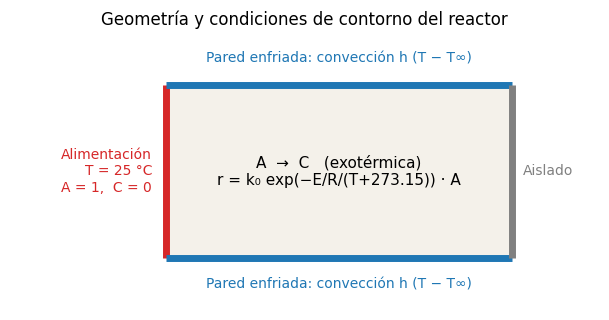

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.add_patch(patches.Rectangle((0, 0), 1.0, 0.5, facecolor='#f4f1ea', edgecolor='none'))
ax.plot([0, 0], [0, 0.5], color='tab:red', lw=5, solid_capstyle='butt')
ax.plot([0, 1], [0, 0], color='tab:blue', lw=5, solid_capstyle='butt')
ax.plot([0, 1], [0.5, 0.5], color='tab:blue', lw=5, solid_capstyle='butt')
ax.plot([1, 1], [0, 0.5], color='gray', lw=5, solid_capstyle='butt')
ax.text(0.5, 0.25, 'A  →  C   (exotérmica)\nr = k₀ exp(−E/R/(T+273.15)) · A', ha='center', va='center', fontsize=11)
ax.text(-0.04, 0.25, 'Alimentación\nT = 25 °C\nA = 1,  C = 0', ha='right', va='center', color='tab:red', fontsize=10)
ax.text(0.5, -0.055, 'Pared enfriada: convección h (T − T∞)', ha='center', va='top', color='tab:blue', fontsize=10)
ax.text(0.5, 0.555, 'Pared enfriada: convección h (T − T∞)', ha='center', va='bottom', color='tab:blue', fontsize=10)
ax.text(1.03, 0.25, 'Aislado', ha='left', va='center', color='gray', fontsize=10)
ax.set_xlim(-0.45, 1.25)
ax.set_ylim(-0.15, 0.65)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Geometría y condiciones de contorno del reactor')
plt.show()

## 2. Preparación del entorno

Se importa solo lo necesario. Cada módulo de `Source/` tiene una responsabilidad clara:

| Módulo | Para qué sirve |
|---|---|
| `Mesh` | Genera la malla (nodos y elementos) y selecciona bordes. |
| `Model` | Reúne malla, material y física(s); es el punto de entrada para configurar y resolver. |
| `material` | Guarda propiedades del material (`k`, `rho`, `Cp`, ...). |
| `ht` | Física de **transferencia de calor** (conducción, convección, radiación). |
| `mt` | Física de **transporte de especies** (difusión, convección, reacciones). |
| `Discretization`, `Operators` | Capas internas que se muestran en la sección 9 para explicar el cálculo. |
| `enums` | Opciones del solver (estacionario o transitorio, directo o iterativo, ...). |
| `sim_logger` | El registro de la simulación: aquí se ve cada iteración de Newton. |

`scipy.integrate.solve_ivp` se usa solo en la verificación (sección 12), como referencia independiente.

In [2]:
import os, sys, time, logging
import numpy as np
import matplotlib.tri as mtri
from scipy.integrate import solve_ivp

sys.path.insert(0, os.getcwd())          # el cuaderno vive en la raíz del proyecto
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.HeatTransfer import ht
from Source.Physics.MassTransfer import mt
from Source.Simulation.Discretization import Discretization
import Source.Simulation.Operators as ops
from Source.enums import ElementType, StudyType, ProblemType, SolverType, DirectSolvers
from Source.logger_config import sim_logger

print("Módulos importados. Directorio de trabajo:", os.getcwd())

Módulos importados. Directorio de trabajo: D:\Documentos\Python Scripts\FEM-sim


## 3. Parámetros del modelo

Todo es **adimensional**: lo importante es la forma en que se acoplan las físicas, no las unidades concretas.

| Símbolo | Variable | Valor | Significado |
|---|---|---|---|
| $k$ | `k_cond` | 2.0 | Conductividad térmica del medio |
| $\rho C_p$ | `rho_cp` | 5.0 | Capacidad calorífica volumétrica (solo importa en el transitorio) |
| $D$ | `D` | 1.0 | Difusividad de A y de C. **Igual para las dos**: eso produce un invariante exacto que usaremos para verificar |
| $k_0$ | `k0` | $3\times10^{4}$ | Factor de frecuencia de la reacción |
| $E_R$ | `E_R` | 2000 K | Energía de activación dividida por $R$ |
| $Q$ | `Q_react` | 80 | Calor liberado por mol que reacciona, $-\Delta H$ |
| $T_\infty$ | `T_amb` | 25 °C | Temperatura de alimentación y del ambiente |
| $h$ | `h_wall` | 4.0 | Coeficiente de convección de las paredes |
| | `Lx, Ly, nx, ny` | 1, 0.5, 40, 20 | Tamaño de la placa y número de elementos en cada dirección |

In [3]:
k_cond, rho_cp, D = 2.0, 5.0, 1.0       # conductividad, capacidad calorífica volumétrica, difusividad
k0, E_R = 3.0e4, 2000.0                 # Arrhenius: factor de frecuencia y E/R [K]
Q_react = 80.0                          # calor de reacción Q = -dH
T_amb, h_wall = 25.0, 4.0               # ambiente [°C] y coeficiente de convección de las paredes
Lx, Ly, nx, ny = 1.0, 0.5, 40, 20       # placa y malla

# Efecto del acoplamiento en una cifra: temperatura adiabática alcanzable si todo A reaccionara en un punto
print(f"Aumento adiabático de temperatura (Q·A0/rho_cp) = {Q_react * 1.0 / rho_cp:.1f} °C")
print(f"Velocidad específica de reacción a {T_amb:.0f} °C: k(T) = {k0 * np.exp(-E_R / (T_amb + 273.15)):.1f} 1/s")

Aumento adiabático de temperatura (Q·A0/rho_cp) = 16.0 °C
Velocidad específica de reacción a 25 °C: k(T) = 36.6 1/s


## 4. La malla

La placa se discretiza con **elementos cuadriláteros bilineales (Q4)**. `generate2DMesh((Lx, Ly), (nx, ny), tipo)` crea
`nx × ny` elementos y numera los nodos **a lo largo de x primero**. Cada elemento lista sus cuatro nodos en sentido
**antihorario**, empezando por la esquina inferior izquierda (esquina 0, 1, 2, 3). Esa convención garantiza que el jacobiano
de la transformación sea positivo.

In [4]:
mesh = Mesh()
mesh.generate2DMesh((Lx, Ly), (nx, ny), ElementType.quadrilateral)

print(f"Nodos: {mesh.getNoN()}   Elementos: {mesh.getNoE()}")
print("Nodo 0  :", mesh.NL[0].coor, "  (esquina inferior izquierda)")
print("Nodo 1  :", mesh.NL[1].coor, "  (siguiente nodo en x)")
print(f"Nodo {nx + 1}:", mesh.NL[nx + 1].coor, "  (primer nodo de la segunda fila)")
element = mesh.EL[0]
print("Elemento 0 -> nodos", element.getNodesId(), "con coordenadas", element.getCoor())

Nodos: 861   Elementos: 800
Nodo 0  : (0.0, 0.0)   (esquina inferior izquierda)
Nodo 1  : (0.025, 0.0)   (siguiente nodo en x)
Nodo 41: (0.0, 0.025)   (primer nodo de la segunda fila)
Elemento 0 -> nodos [0, 1, 42, 41] con coordenadas [(0.0, 0.0), (0.025, 0.0), (0.025, 0.025), (0.0, 0.025)]


Para ver la numeración con claridad se dibuja una malla pequeña de $4 \times 2$ elementos (la del modelo tiene $40 \times 20$):

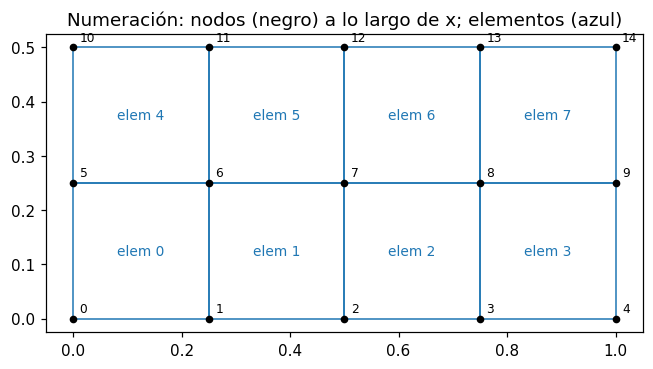

In [5]:
small = Mesh()
small.generate2DMesh((1.0, 0.5), (4, 2), ElementType.quadrilateral)

fig, ax = plt.subplots(figsize=(7, 3.6))
for element in small.EL:
    corners = np.array(element.getCoor())
    ax.add_patch(patches.Polygon(corners, closed=True, fill=False, edgecolor='tab:blue'))
    centre = corners.mean(axis=0)
    ax.text(centre[0], centre[1], f"elem {element.id}", ha='center', va='center', color='tab:blue', fontsize=9)
for node in small.NL:
    ax.plot(*node.coor, 'ko', ms=4)
    ax.text(node.coor[0] + 0.012, node.coor[1] + 0.012, str(node.id), fontsize=8)
ax.set_aspect('equal'); ax.grid(False)
ax.set_title('Numeración: nodos (negro) a lo largo de x; elementos (azul)')
plt.show()

### Selección de bordes

Las condiciones de contorno se aplican sobre **bordes** (aristas de elementos que pertenecen a un solo elemento).
`mesh.boundary_edges(predicado)` devuelve los bordes del contorno cuyo **punto medio** `(x, y)` cumple el predicado.
Cada borde es una pareja de nodos.

Alimentación: 20 bordes, por ejemplo [(41, 0), (82, 41), (123, 82)]
Paredes     : 80 bordes
Derecho     : 20 bordes
Todo el contorno: 120 bordes (= 2·(40+20) = 120)


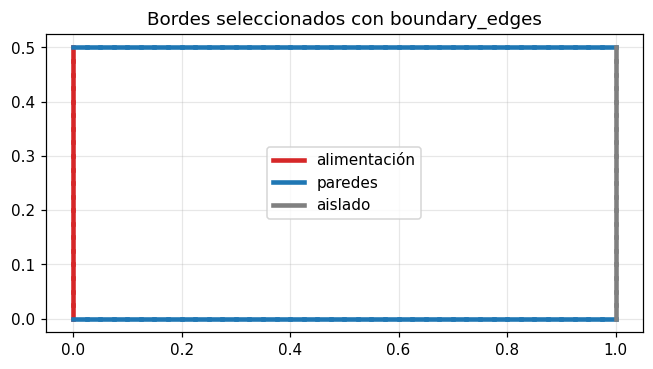

In [6]:
feed = mesh.boundary_edges(lambda x, y: x < 1e-12)                          # borde izquierdo: alimentación
walls = mesh.boundary_edges(lambda x, y: y < 1e-12 or y > Ly - 1e-12)       # paredes superior e inferior
insulated = mesh.boundary_edges(lambda x, y: x > Lx - 1e-12)                # borde derecho

print(f"Alimentación: {len(feed)} bordes, por ejemplo {feed[:3]}")
print(f"Paredes     : {len(walls)} bordes")
print(f"Derecho     : {len(insulated)} bordes")
print(f"Todo el contorno: {len(mesh.boundary_edges())} bordes (= 2·({nx}+{ny}) = {2 * (nx + ny)})")

xy = np.array([node.coor for node in mesh.NL])
fig, ax = plt.subplots(figsize=(7, 3.6))
for group, color, label in ((feed, 'tab:red', 'alimentación'), (walls, 'tab:blue', 'paredes'), (insulated, 'gray', 'aislado')):
    for k, (a, b) in enumerate(group):
        ax.plot(*zip(xy[a], xy[b]), color=color, lw=3, label=label if k == 0 else None)
ax.set_aspect('equal'); ax.legend(loc='center'); ax.set_title('Bordes seleccionados con boundary_edges')
plt.show()

## 5. El modelo con dos físicas

Aquí está la idea central. `Model(..., psc=[ht, mt])` recibe una **lista** de físicas:

1. `material('Medio', k=..., rho=..., Cp=...)` guarda las propiedades. La física de calor toma de ahí la conductividad `k` y la
   capacidad `rho·Cp`.
2. Con una lista, `Model` crea un `CoupledPhysics`, que **instancia cada física** y las expone por nombre:
   `model.physics.heat` (calor, de `ht`) y `model.physics.mass` (especies, de `mt`).
3. Los campos de ambas se **unen** en un solo conjunto de incógnitas, y más adelante todos los términos se ensamblan en un
   **único sistema** (sección 9). Por eso un término de una física puede depender de un campo de la otra.

In [7]:
model = Model(name='Reactor_placa', dim=2, mesh=mesh,
              mat=material('Medio', k=k_cond, rho=rho_cp, Cp=1.0),
              psc=[ht, mt])

heat, mass = model.physics.heat, model.physics.mass        # cada física, por nombre

print(model)
print()
print("Tipo de física del modelo:", type(model.physics).__name__)
print("Partes:", {name: type(part).__name__ for name, part in model.physics.parts.items()})

Model: Reactor_placa
Dimension: 2D
Nodes: 861
Elements: 800
Physics: Heat transfer + Transport of Chemical Species

Tipo de física del modelo: CoupledPhysics
Partes: {'heat': 'ht', 'mass': 'mt'}


**Dos formas de llamar a los métodos.** Los métodos de cada parte se pueden llamar directamente sobre la combinación
(`model.physics.addBC_Temperature(...)`) o sobre la parte (`heat.addBC_Temperature(...)`); es lo mismo. En cambio,
**asignar** un atributo (por ejemplo `Convection = True`) debe hacerse sobre la parte. Si se intenta sobre la combinación, el
programa lo rechaza, para que el valor nunca se pierda en silencio:

In [8]:
try:
    model.physics.Convection = True            # incorrecto: este atributo pertenece a una parte
except AttributeError as error:
    print("Error esperado ->", error)

heat.Convection = False                        # correcto: sin transporte convectivo de calor
mass.Convection = False                        # ni de especies: solo difusión y reacción

Error esperado -> Asigne 'Convection' en la parte: model.physics.heat.Convection = ...


### Las especies

`mass.setChemSpecies(nombre, descripción)` crea un campo de concentración. `mass.setDiffusivity(nombre, D)` asigna su
difusividad: un número, o una función de las coordenadas $D(x, y)$.

In [9]:
for species in ('A', 'C'):
    mass.setChemSpecies(species, f'Componente {species}')
    mass.setDiffusivity(species, D)

print("Variables del modelo (todas las físicas):", list(model.physics.var))
print("Estado del modelo:", model.physics_status)

Variables del modelo (todas las físicas): ['T', 'A', 'C']
Estado del modelo: Heat transfer + Transport of Chemical Species


### Los grados de libertad

Cada campo tiene un valor en cada nodo. El modelo numera las incógnitas **por nodo**: primero las tres de un nodo, luego las
del siguiente. Es el `DofLayout`:

$$\text{dof} = \text{nodo} \times n_{\text{campos}} + \text{desplazamiento del campo}$$

In [10]:
layout = model.layout
print("Campos           :", layout.names)
print("Incógnitas/nodo  :", layout.n_total)
print("Grados de libertad totales:", layout.ndof, f"= {mesh.getNoN()} nodos × {layout.n_total} campos")
print()
for name in layout.names:
    print(f"  DOF de {name} en los nodos 0, 1, 2, 3 ->", layout.dofs(name)[:4, 0])

Campos           : ['T', 'A', 'C']
Incógnitas/nodo  : 3
Grados de libertad totales: 2583 = 861 nodos × 3 campos

  DOF de T en los nodos 0, 1, 2, 3 -> [0 3 6 9]
  DOF de A en los nodos 0, 1, 2, 3 -> [ 1  4  7 10]
  DOF de C en los nodos 0, 1, 2, 3 -> [ 2  5  8 11]


## 6. La reacción

`mass.addReaction(estequiometría, k0, E_R, T, orden, dH)` declara una reacción. Cada argumento:

| Argumento | Valor | Significado |
|---|---|---|
| `stoich` | `{'A': -1, 'C': 1}` | Coeficientes estequiométricos $\nu$: negativos para reactivos, positivos para productos |
| `k0` | `3e4` | Factor de frecuencia de Arrhenius |
| `E_R` | `2000` | $E/R$ en Kelvin |
| `T` | `'T'` | **Nombre del campo de temperatura.** Con un número (Kelvin) la reacción sería isotérmica; con `'T'` usa la temperatura que calcula el propio modelo |
| `order` | `{'A': 1}` | Orden de reacción respecto de cada especie (primer orden en A) |
| `dH` | `-80` | Calor de reacción [J/mol]. Negativo = exotérmico; libera $-dH \cdot r$ al campo `T` |

Dos detalles de unidades: el campo `T` está en **°C**, así que la ley suma 273.15 antes de aplicar Arrhenius; y `dH` solo tiene
sentido si `T` es un campo (si no, no habría dónde liberar el calor) y el programa lo exige.

In [11]:
mass.addReaction({'A': -1, 'C': 1}, k0=k0, E_R=E_R, T='T', order={'A': 1}, dH=-Q_react)

print("Reacciones declaradas:")
for reaction in mass.reactions:
    print("  ", reaction)

Reacciones declaradas:
   {'stoich': {'A': -1, 'C': 1}, 'k0': 30000.0, 'E_R': 2000.0, 'T': 'T', 'order': {'A': 1, 'C': 0}, 'dH': -80.0}


### Qué se construye con esa declaración

La reacción se convierte en **una ley puntual** (`PointwiseLaw`): una función de los valores locales de los campos que devuelve
la producción de cada especie y el calor liberado. Su particularidad es que el programa calcula **automáticamente su derivada**
(diferenciación automática con JAX), que necesita Newton. Se puede consultar directamente:

In [12]:
law, inputs, outputs = mass.reaction_law()
print("La ley LEE los campos   :", inputs)
print("La ley ESCRIBE en       :", outputs)

# Estado local de prueba: A = 0.8, C = 0.2, T = 60 °C
state = np.array([[0.8, 0.2, 60.0]])
values, derivatives = law(state)

r_manual = k0 * np.exp(-E_R / (60.0 + 273.15)) * 0.8
print(f"\nVelocidad de reacción r a mano        : {r_manual:.6f}")
print(f"Producción de A, C y calor de la ley : {values[0].round(6)}   (esperado: -r, +r, Q·r = {Q_react * r_manual:.6f})")

def show_table(matrix, rows, columns, title):
    print(title)
    print("          " + "".join(f"{c:>12}" for c in columns))
    for name, row in zip(rows, matrix):
        print(f"{name:>10}" + "".join(f"{v:12.4f}" for v in row))

show_table(derivatives[0], ['prod. A', 'prod. C', 'calor'], ['d/dA', 'd/dC', 'd/dT'],
           "\nJacobiano de la ley (calculado por autodiff):")

La ley LEE los campos   : ['A', 'C', 'T']
La ley ESCRIBE en       : ['A', 'C', 'T']

Velocidad de reacción r a mano        : 59.293951
Producción de A, C y calor de la ley : [ -59.293951   59.293951 4743.516077]   (esperado: -r, +r, Q·r = 4743.516077)

Jacobiano de la ley (calculado por autodiff):
                  d/dA        d/dC        d/dT
   prod. A    -74.1174     -0.0000     -1.0685
   prod. C     74.1174      0.0000      1.0685
     calor   5929.3951      0.0000     85.4773


Interpretación de la tabla de derivadas, que es el **acoplamiento hecho números**:

- `d(prod. A)/dA` y `d(prod. C)/dA`: más reactivo, más reacción (acoplamiento entre especies).
- `d(prod. ·)/dT`: **la temperatura acelera la reacción** (Arrhenius). Esto es lo que enlaza el calor con las especies.
- `d(calor)/dA` y `d(calor)/dT`: el calor liberado depende de cuánto reactivo hay y de la temperatura. Esto cierra el lazo.
- Las derivadas respecto de `C` son cero: la reacción no depende del producto.

## 7. Condiciones de contorno e iniciales

### Convención de signos

Todos los flujos de contorno se definen **salientes** del dominio:

- Convección: $q = h\,(T - T_\infty)$ sale del dominio si la superficie está más caliente que el ambiente.
- Flujo prescrito (Neumann): $q = -k\,\partial T/\partial n$ con $n$ apuntando hacia afuera.
- Un borde **sin condición** es aislado/sin flujo: es la condición **natural** de elementos finitos, no hay que declararla.

### Dónde se guarda cada condición

- Dirichlet (valor fijo): se guarda **en cada nodo** del borde, en `node.BC[campo]`.
- Convección: se guarda en `physics.facet_bcs`, como una condición sobre **bordes** (se integra a lo largo de cada borde).

In [13]:
heat.addBC_TemperatureEdges(feed, T_amb)               # Dirichlet de temperatura en la alimentación
heat.addBC_ConvectionEdges(walls, h_wall, T_amb)       # convección en las paredes: q = h (T - T_amb)
mass.addBC_ConcentrationEdges(feed, 'A', 1.0)          # Dirichlet de A en la alimentación
mass.addBC_ConcentrationEdges(feed, 'C', 0.0)          # y de C
# El borde derecho no necesita nada: sin flujo es la condición natural.

print("Condiciones del nodo 0 (esquina de la alimentación):")
for field, bc in mesh.NL[0].BC.items():
    print(f"   {field}: {bc}")

print("\nCondición de convección guardada en la física de calor:")
bc = heat.facet_bcs[0]
print(f"   tipo={bc['type']}, campo={bc['field']}, bordes={len(bc['facets'])}, h={bc['h']}, T_ext={bc['var_ext']}")

Condiciones del nodo 0 (esquina de la alimentación):
   T: {'type': 'Dirichlet', 'value': 25.0}
   A: {'type': 'Dirichlet', 'value': 1.0}
   C: {'type': 'Dirichlet', 'value': 0.0}

Condición de convección guardada en la física de calor:
   tipo=Newton, campo=T, bordes=80, h=4.0, T_ext=25.0


### Condiciones iniciales

`initField(campo, valor)` fija el estado de partida. Acepta un **número** (campo uniforme) o una **función** de las coordenadas
(`lambda x, y: ...`). En un problema estacionario es el punto de partida del método de Newton; en uno transitorio es el estado
en $t = 0$. Aquí se parte de un estado frío con algo de reactivo.

In [14]:
model.physics.initField('T', T_amb)       # placa a temperatura ambiente
model.physics.initField('A', 0.5)         # algo de reactivo en todo el dominio
model.physics.initField('C', 0.0)         # sin producto

print("T inicial: mín/máx =", np.min(model.physics.var['T'].values), np.max(model.physics.var['T'].values))
print("A inicial: mín/máx =", np.min(model.physics.var['A'].values), np.max(model.physics.var['A'].values))

T inicial: mín/máx = 25.0 25.0
A inicial: mín/máx = 0.5 0.5


## 8. Configuración del solver

`model.solverConfiguration(...)` solo **guarda las opciones**; el cálculo ocurre en `model.solve()`.

| Opción | Valor | Significado |
|---|---|---|
| `Study` | `StudyType.steady_state` | Estacionario: se busca el estado en que nada cambia con el tiempo. La alternativa es `StudyType.transient` |
| `Type` | `ProblemType.nonlinear` | El problema es **no lineal** (la reacción depende de $T$ y de $A$ de forma no lineal), así que se resuelve con Newton-Raphson. Con un problema lineal bastaría `ProblemType.linear` |
| `Method` | `SolverType.direct` | Cada sistema lineal se resuelve con un método **directo** (factorización). La alternativa es `SolverType.iterative` |
| `Solver` | `DirectSolvers.PARDISO` | La factorización directa que se usa (`PARDISO`, o `SuperLU`) |

Para estudios transitorios se añaden `timeDisc` ($\theta$ del método: 1 = Euler implícito, 0.5 = Crank-Nicolson), `timeStep` ($\Delta t$) y
`totalTime`; se usan en la sección 13.

In [15]:
model.solverConfiguration(Study=StudyType.steady_state,
                          Type=ProblemType.nonlinear,
                          Method=SolverType.direct,
                          Solver=DirectSolvers.PARDISO)
print("Opciones guardadas:", {k: (v.name if hasattr(v, 'name') else v) for k, v in model.solverOptions.items() if k in ('Study', 'Type', 'Method', 'Solver')})

Opciones guardadas: {'Study': 'steady_state', 'Type': 'nonlinear', 'Method': 'direct', 'Solver': 'PARDISO'}


Para reutilizar el montaje en las secciones siguientes, se condensan **todos los pasos anteriores** en una función
(el mismo código, con el calor de reacción $Q$ y el tamaño de malla como parámetros):

In [16]:
def build_plate(Q, nx=nx, ny=ny):
    # Reactor de placa con calor de reacción Q = -dH (Q = 0 desactiva la liberación de calor).
    m = Mesh()
    m.generate2DMesh((Lx, Ly), (nx, ny), ElementType.quadrilateral)
    mod = Model(name='Reactor_placa', dim=2, mesh=m, mat=material('Medio', k=k_cond, rho=rho_cp, Cp=1.0), psc=[ht, mt])
    h_part, m_part = mod.physics.heat, mod.physics.mass
    h_part.Convection = False
    m_part.Convection = False
    for species in ('A', 'C'):
        m_part.setChemSpecies(species, species)
        m_part.setDiffusivity(species, D)
    m_part.addReaction({'A': -1, 'C': 1}, k0=k0, E_R=E_R, T='T', order={'A': 1}, dH=-Q if Q else None)
    feed_edges = m.boundary_edges(lambda x, y: x < 1e-12)
    wall_edges = m.boundary_edges(lambda x, y: y < 1e-12 or y > Ly - 1e-12)
    h_part.addBC_TemperatureEdges(feed_edges, T_amb)
    h_part.addBC_ConvectionEdges(wall_edges, h_wall, T_amb)
    m_part.addBC_ConcentrationEdges(feed_edges, 'A', 1.0)
    m_part.addBC_ConcentrationEdges(feed_edges, 'C', 0.0)
    mod.physics.initField('T', T_amb)
    mod.physics.initField('A', 0.5)
    mod.physics.initField('C', 0.0)
    mod.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear,
                            Method=SolverType.direct, Solver=DirectSolvers.PARDISO)
    return mod


class _Capture(logging.Handler):
    # Guarda los mensajes del registro para leer el número de iteraciones de Newton.
    def __init__(self):
        super().__init__()
        self.messages = []

    def emit(self, record):
        self.messages.append(record.getMessage())


def solve_quiet(mod):
    # Resuelve sin imprimir el registro; devuelve (iteraciones de Newton, convergió, segundos).
    consoles = [h for h in sim_logger.handlers if type(h) is logging.StreamHandler]
    levels = [h.level for h in consoles]
    capture = _Capture()
    for h in consoles:
        h.setLevel(logging.ERROR)
    sim_logger.addHandler(capture)
    start = time.time()
    try:
        mod.solve()
    finally:
        sim_logger.removeHandler(capture)
        for h, level in zip(consoles, levels):
            h.setLevel(level)
    text = " ".join(capture.messages)
    converged = 'Succefully converged' in text
    iterations = int(text.split('converged in ')[1].split()[0]) if converged else None
    return iterations, converged, time.time() - start


def plot_field(ax, mod, values, title, cmap='viridis', label=None, vmin=None, vmax=None):
    # Contornos rellenos de un campo nodal sobre la malla del modelo (cada Q4 se divide en dos triángulos).
    # vmin/vmax fijan el rango de color (para comparar instantes o evitar contornos ruidosos en campos uniformes).
    pts = np.array([n.coor[:2] for n in mod.mesh.NL])
    tris = []
    for e in mod.mesh.EL:
        a, b, c, d = e.getNodesId()
        tris += [[a, b, c], [a, c, d]]
    levels = np.linspace(vmin, vmax, 31) if vmin is not None and vmax is not None else 30
    cs = ax.tricontourf(mtri.Triangulation(pts[:, 0], pts[:, 1], tris), values, levels=levels, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(cs, ax=ax, label=label, shrink=0.85)
    ax.set_aspect('equal'); ax.grid(False)
    ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y')

print("Funciones auxiliares definidas: build_plate, solve_quiet, plot_field")

Funciones auxiliares definidas: build_plate, solve_quiet, plot_field


## 9. Qué ocurre dentro de la simulación

`model.solve()` hace, en orden: **(a)** calcular la geometría de la malla, **(b)** ensamblar el sistema de ecuaciones con los
términos de las dos físicas, **(c)** iterar con Newton-Raphson hasta convergencia. Se muestra cada paso.

### 9.1 Geometría: integración numérica en cada elemento

Cada elemento se integra con una **cuadratura de Gauss de 2×2 puntos**. `Discretization` precalcula, **una vez** y para toda
la malla a la vez:

| Magnitud | Forma | Qué es |
|---|---|---|
| `N` | (puntos, nodos del elemento) | Funciones de forma en los puntos de Gauss |
| `B` | (elementos, puntos, nodos, 2) | Gradientes de las funciones de forma en coordenadas físicas |
| `detJw` | (elementos, puntos) | Determinante del jacobiano por el peso de Gauss: el "diferencial de área" |
| `x_gp` | (elementos, puntos, 2) | Coordenadas físicas de los puntos de Gauss |

conn  (nodos de cada elemento) : (800, 4)
N     (funciones de forma)     : (4, 4)
B     (gradientes)             : (800, 4, 4, 2)
detJw (diferencial de área)    : (800, 4)
x_gp  (puntos de Gauss)        : (800, 4, 2)

Suma de detJw = 0.500000  (debe ser el área de la placa, 0.5)


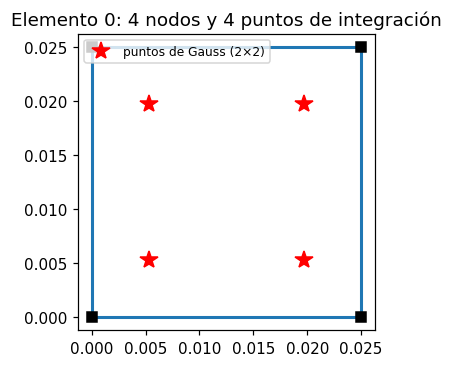

In [17]:
disc = Discretization(mesh)
print("conn  (nodos de cada elemento) :", disc.conn.shape)
print("N     (funciones de forma)     :", disc.N.shape)
print("B     (gradientes)             :", disc.B.shape)
print("detJw (diferencial de área)    :", disc.detJw.shape)
print("x_gp  (puntos de Gauss)        :", disc.x_gp.shape)
print(f"\nSuma de detJw = {disc.detJw.sum():.6f}  (debe ser el área de la placa, {Lx * Ly})")

e = 0
fig, ax = plt.subplots(figsize=(4.5, 3.5))
corners = disc.node_xy[disc.conn[e]]
ax.add_patch(patches.Polygon(corners, closed=True, fill=False, edgecolor='tab:blue', lw=2))
ax.plot(*corners.T, 'ks')
ax.plot(*disc.x_gp[e].T, 'r*', ms=12, label='puntos de Gauss (2×2)')
ax.set_aspect('equal'); ax.legend(loc='upper left', fontsize=8); ax.grid(False)
ax.set_title(f'Elemento {e}: 4 nodos y 4 puntos de integración')
plt.show()

### 9.2 El sistema: matrices, términos no lineales y condiciones

Cada física **añade sus términos** a un único `System`. Las integrales se calculan para todos los elementos a la vez con
operadores vectorizados (`Operators`):

| Término | Operador | Quién lo añade |
|---|---|---|
| Difusión de calor $\int k\,\nabla N_i\cdot\nabla N_j$ | `ops.diffusion` | `ht` |
| Difusión de cada especie $\int D\,\nabla N_i\cdot\nabla N_j$ | `ops.diffusion` | `mt` |
| Masa $\int c\,N_iN_j$ (solo para el transitorio) | `ops.mass` | ambas |
| **Reacción y calor liberado** (no lineal, acopla T, A y C) | `PointwiseLaw` | `mt` |
| Convección en paredes $\int h\,N_iN_j$ y $\int h\,T_\infty N_i$ | `ops.facet_mass`, `ops.facet_source` | condiciones de contorno |
| Valores fijos (Dirichlet) | filas identidad | condiciones de contorno |

El resultado se consulta con `model._system()` (método interno, usado aquí solo para inspeccionar):

In [18]:
system = model._system()
state0 = model._state()                    # vector con T, A y C de todos los nodos, en el orden de los DOF

print("Incógnitas totales            :", layout.ndof)
print("Incógnitas fijadas (Dirichlet):", int(system.is_dirichlet.sum()))
print("Términos no lineales          :", [type(t).__name__ for t in system._terms])
print("Entradas no nulas de la parte lineal (difusión + convección):", system._A.nnz)
print("Matriz de masa                :", system.mass().shape, "con", system.mass().nnz, "entradas")

# Ejemplo de operador: la matriz de difusión de UN elemento, 4×4
Ke = ops.diffusion(disc, k_cond)[0]
print("\nMatriz de difusión del elemento 0 (4×4):")
print(np.array2string(Ke, precision=3, suppress_small=True))
print("Suma de cada fila =", Ke.sum(axis=1).round(12), "(una temperatura uniforme no genera flujo)")

Incógnitas totales            : 2583
Incógnitas fijadas (Dirichlet): 63
Términos no lineales          : ['VolumeLawTerm']
Entradas no nulas de la parte lineal (difusión + convección): 22143
Matriz de masa                : (2583, 2583) con 22143 entradas

Matriz de difusión del elemento 0 (4×4):
[[ 1.333 -0.333 -0.667 -0.333]
 [-0.333  1.333 -0.333 -0.667]
 [-0.667 -0.333  1.333 -0.333]
 [-0.333 -0.667 -0.333  1.333]]
Suma de cada fila = [-0. -0.  0.  0.] (una temperatura uniforme no genera flujo)


### 9.3 El jacobiano y el acoplamiento

Newton-Raphson necesita el **jacobiano** $J = \partial R / \partial x$ del residuo $R$ (cuánto cambia cada ecuación al variar
cada incógnita). Como hay tres campos, $J$ se organiza en **bloques** 3×3: fila = ecuación de un campo, columna = derivada
respecto de otro campo. Los bloques fuera de la diagonal **son el acoplamiento**.

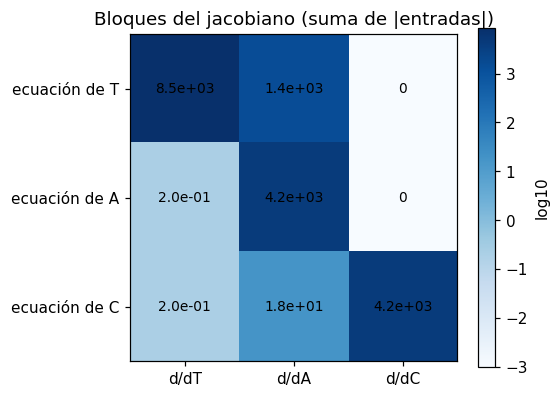

In [19]:
J, R = system.residual_and_tangent(state0)
Jc = J.tocsr()

names = layout.names
blocks = np.zeros((3, 3))
for i, row in enumerate(names):
    for j, col in enumerate(names):
        sub = Jc[layout.dofs(row)[:, 0]][:, layout.dofs(col)[:, 0]]
        blocks[i, j] = abs(sub).sum()

fig, ax = plt.subplots(figsize=(4.8, 4))
image = ax.imshow(np.log10(blocks + 1e-3), cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels([f'd/d{n}' for n in names])
ax.set_yticks(range(3)); ax.set_yticklabels([f'ecuación de {n}' for n in names])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{blocks[i, j]:.1e}" if blocks[i, j] > 0 else "0", ha='center', va='center', fontsize=9)
ax.grid(False)
ax.set_title('Bloques del jacobiano (suma de |entradas|)')
plt.colorbar(image, ax=ax, label='log10')
plt.show()

Cómo leer el mapa:

- **Diagonal** (T-T, A-A, C-C): la difusión de cada campo.
- **Fila T, columna A y T**: el calor liberado depende de cuánto reactivo hay y de la temperatura.
- **Fila A y C, columna T**: la reacción de cada especie depende de la temperatura (Arrhenius). Es la otra mitad del lazo.
- **Fila A y C, columna A**: la reacción consume reactivo y produce producto.
- **Ceros** (columna C en las filas T y A): ni la temperatura ni el reactivo dependen del producto, porque la reacción no depende de C.

Sin acoplamiento (dos físicas independientes) los bloques fuera de la diagonal entre `T` y las especies serían cero.
La **magnitud** de cada bloque depende de las unidades de cada ecuación (por eso el calor responde mucho más al reactivo que
la reacción a la temperatura en esta escala); lo que importa es que **no son cero**.

### 9.4 Por qué se escala el residuo

La temperatura es del orden de 25–300 y las concentraciones del orden de 1. Si el criterio de Newton mirara el residuo tal cual,
las ecuaciones de la temperatura dominarían la norma. Por eso el solver **escala cada fila del residuo con la diagonal del
jacobiano inicial**: así cada ecuación queda expresada en las unidades de su propia incógnita.

In [20]:
rows = {n: layout.dofs(n)[:, 0] for n in names}
diagonal = np.maximum(np.abs(J.diagonal()), 1.0)

print(f"{'campo':>6} {'||R|| sin escalar':>20} {'||R|| escalado':>16}")
for n in names:
    print(f"{n:>6} {np.linalg.norm(R[rows[n]]):>20.3e} {np.linalg.norm(R[rows[n]] / diagonal[rows[n]]):>16.3e}")

 campo    ||R|| sin escalar   ||R|| escalado
     T            2.534e+01        4.974e+00
     A            2.313e+00        2.295e+00
     C            3.167e-01        1.243e-01


### 9.5 Newton-Raphson

Se repite hasta converger:

1. Se calcula el residuo $R(x)$ y el jacobiano $J(x)$ con el estado actual (el `System` lo ensambla).
2. Se resuelve el sistema lineal $J\,\Delta x = -R$ con el método directo.
3. **Búsqueda de línea:** se prueba el paso completo $x + \Delta x$; si el residuo escalado no disminuye, se divide el paso por 2
   hasta que mejore (columna `Alpha` del registro: 1 = paso completo).
4. Se detiene cuando el residuo escalado cae por debajo de $10^{-10}$ veces el inicial (o por debajo de $10^{-10}$ en términos
   absolutos).

Como es un método de segundo orden, una vez cerca de la solución cada iteración **eleva al cuadrado** el error: el residuo cae
de $10^{-3}$ a $10^{-6}$ a $10^{-12}$.

## 10. Resolver y mostrar los resultados

`model.solve()` ejecuta todo lo anterior. El **registro** que imprime es la traza real de Newton: iteración, norma del residuo
escalado, su valor relativo al inicial y el factor de paso `Alpha`.

In [21]:
start = time.time()
model.solve()
print(f"\nTiempo de cálculo: {time.time() - start:.3f} s para {layout.ndof} incógnitas")

2026-10-27 22:29:31 - INFO - ------- Starting simulation -------
2026-10-27 22:29:31 - INFO - Model: Reactor_placa
2026-10-27 22:29:31 - INFO - Dimension: 2D
2026-10-27 22:29:31 - INFO - Nodes: 861
2026-10-27 22:29:31 - INFO - Elements: 800
2026-10-27 22:29:31 - INFO - Physics: Heat transfer + Transport of Chemical Species
2026-10-27 22:29:31 - INFO - ------- Solver configuration -------
2026-10-27 22:29:31 - INFO - Study: Steady state
2026-10-27 22:29:31 - INFO - Type: Nonlinear
2026-10-27 22:29:31 - INFO - Method: Direct
2026-10-27 22:29:31 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-10-27 22:29:31 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-10-27 22:29:31 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-10-27 22:29:31 - INFO - -----------------------------------------------------------
2026-10-27 22:29:31 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-10-27 22


Tiempo de cálculo: 0.268 s para 2583 incógnitas


Los resultados quedan en `model.sol[campo]`, un vector con el valor nodal de cada campo:

Temperatura: mín 25.00 °C, máx 42.63 °C  (la alimentación se mantiene a 25 °C)
Reactivo A : mín 0.0022, máx 1.0000
Producto C : mín 0.0000, máx 0.9978


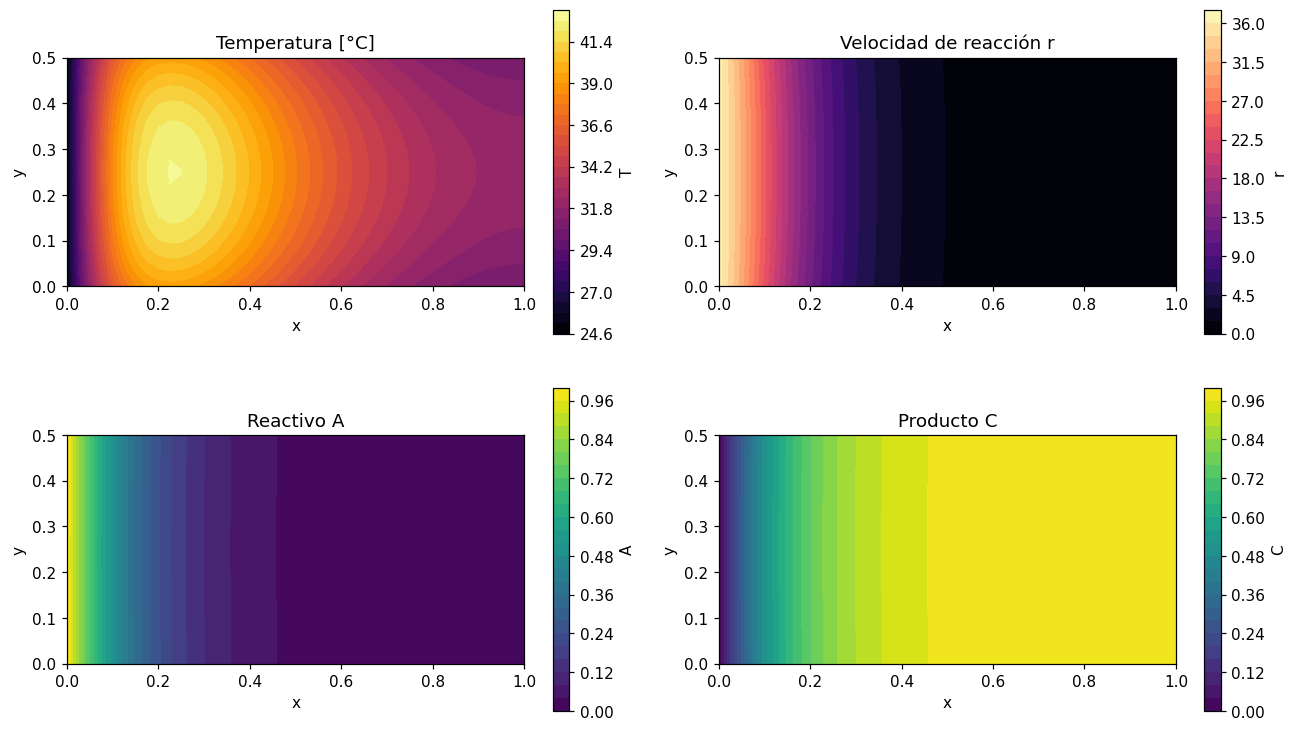

In [22]:
T = np.asarray(model.sol['T'])
A = np.asarray(model.sol['A'])
C = np.asarray(model.sol['C'])
r_nodal = k0 * np.exp(-E_R / (T + 273.15)) * A       # velocidad de reacción en cada nodo

print(f"Temperatura: mín {T.min():.2f} °C, máx {T.max():.2f} °C  (la alimentación se mantiene a {T_amb:.0f} °C)")
print(f"Reactivo A : mín {A.min():.4f}, máx {A.max():.4f}")
print(f"Producto C : mín {C.min():.4f}, máx {C.max():.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
plot_field(axes[0, 0], model, T, 'Temperatura [°C]', 'inferno', 'T')
plot_field(axes[0, 1], model, r_nodal, 'Velocidad de reacción r', 'magma', 'r')
plot_field(axes[1, 0], model, A, 'Reactivo A', 'viridis', 'A')
plot_field(axes[1, 1], model, C, 'Producto C', 'viridis', 'C')
fig.tight_layout()
plt.show()

**Lectura de los mapas.** El reactivo entra por la izquierda y **se consume en la zona cercana a la alimentación** (A cae casi a
cero antes de $x \approx 0.45$); el producto C aparece ahí y se difunde hacia el resto de la placa. Como la reacción ocurre
en esa zona, el calor se genera ahí, y la temperatura máxima aparece **dentro de la placa** ($x \approx 0.23$), no en la
alimentación (que está a 25 °C) ni en el borde aislado. Las paredes frías hacen que la temperatura baje hacia arriba y hacia
abajo.

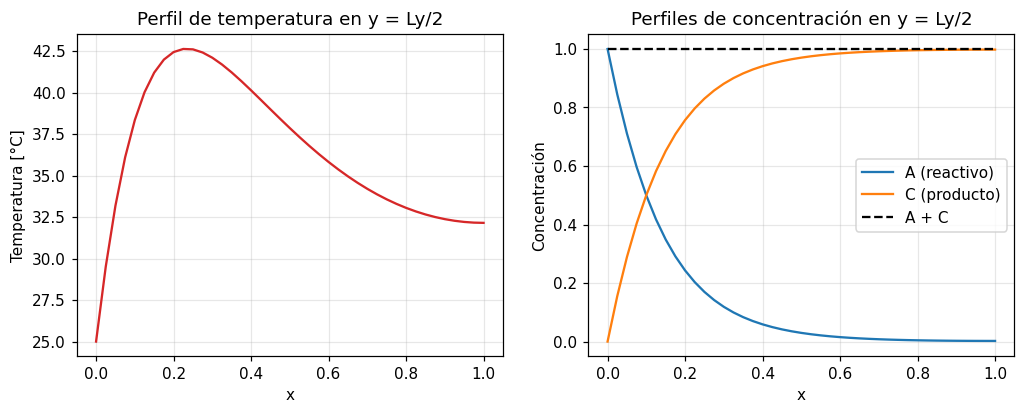

In [23]:
mid = np.isclose(xy[:, 1], Ly / 2)
order = np.argsort(xy[mid, 0])
x_line = xy[mid, 0][order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(x_line, T[mid][order], 'tab:red')
ax1.set_xlabel('x'); ax1.set_ylabel('Temperatura [°C]'); ax1.set_title('Perfil de temperatura en y = Ly/2')
ax2.plot(x_line, A[mid][order], label='A (reactivo)')
ax2.plot(x_line, C[mid][order], label='C (producto)')
ax2.plot(x_line, (A + C)[mid][order], 'k--', label='A + C')
ax2.set_xlabel('x'); ax2.set_ylabel('Concentración'); ax2.set_title('Perfiles de concentración en y = Ly/2'); ax2.legend()
plt.show()

### Dos comprobaciones físicas del resultado

**(1) Un invariante exacto.** Como $A$ y $C$ tienen la misma difusividad, su suma cumple $-\nabla\cdot(D\nabla(A + C)) = 0$:
la reacción se cancela. Con $A + C = 1$ en la alimentación y flujo nulo en el resto de los bordes, $A + C$ debe valer **1 en todas partes**.
Esto es una propiedad exacta también del sistema discreto, y comprueba la estequiometría y el acoplamiento.

**(2) Balance de energía.** Todo el calor que se genera debe salir por las paredes (convección) o por la alimentación (conducción
hacia el borde a 25 °C).

In [24]:
print(f"(1) máx |A + C - 1| = {np.max(np.abs(A + C - 1.0)):.2e}")

# (2) Balance de energía, con cada término calculado por separado
T_g = disc.interpolate(T)
A_g = disc.interpolate(A)
generated = np.sum(disc.detJw * Q_react * k0 * np.exp(-E_R / (T_g + 273.15)) * A_g)       # integral de Q·r

wall_facets = disc.facets(walls)
T_wall = np.einsum('qk,fk->fq', wall_facets.N, T[wall_facets.nodes])
wall_loss = np.sum(wall_facets.detJw * h_wall * (T_wall - T_amb))                           # integral de h (T - T_amb)

residual_free, _ = system._assemble(model._state())[::-1]       # residuo de las ecuaciones sin imponer los Dirichlet
feed_nodes = sorted({n for edge in feed for n in edge})
feed_loss = -residual_free[layout.dofs('T')[feed_nodes, 0]].sum()                           # calor que evacúa la alimentación

print(f"(2) calor generado   = {generated:10.4f}")
print(f"    perdido en paredes = {wall_loss:8.4f}")
print(f"    evacuado por la alimentación = {feed_loss:8.4f}")
print(f"    generado - (paredes + alimentación) = {generated - wall_loss - feed_loss:.2e}")

(1) máx |A + C - 1| = 2.24e-14
(2) calor generado   =   265.5372
    perdido en paredes =  75.0888
    evacuado por la alimentación = 190.4485
    generado - (paredes + alimentación) = -7.28e-12


## 11. Retroalimentación térmica: ¿cuánto importa el acoplamiento?

Se repite el cálculo variando el calor de reacción $Q$. Con $Q = 0$ la reacción **no libera calor**: la placa queda a
25 °C y la reacción es isotérmica (la temperatura sigue en la ley de Arrhenius, pero no cambia). Al aumentar $Q$, la placa se
calienta, la reacción se acelera y consume más reactivo.

     Q  T máx [°C]  Reacción total  Iteraciones Newton   t [s]
----------------------------------------------------------------
     0       25.00          3.0291                   1    0.17
    20       29.11          3.0965                   4    0.27
    40       33.41          3.1672                   5    0.31
    80       42.63          3.3192                   5    0.32
   120       52.75          3.4862                   6    0.35
   200       75.67          3.8687                   7    0.35
   300      109.30          4.4409                   7    0.38
   400      147.52          5.1113                   8    0.44
   600      233.40          6.6727                   9    0.48


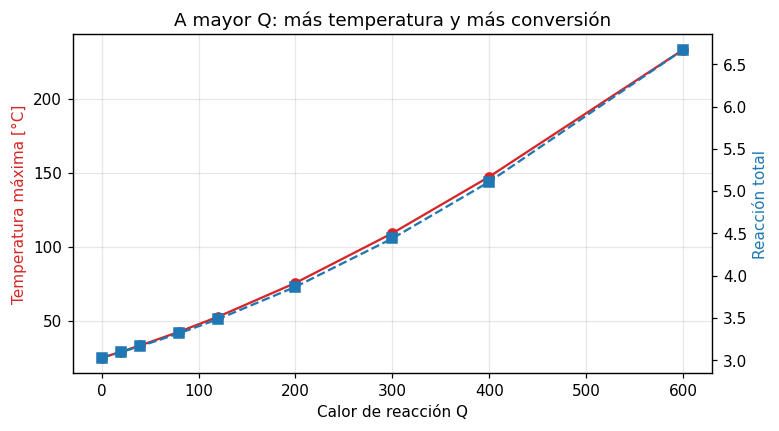

In [25]:
def total_reaction(mod):
    # Integral de la velocidad de reacción sobre la placa (mol/s por unidad de profundidad).
    d = Discretization(mod.mesh)
    T_g = d.interpolate(np.asarray(mod.sol['T']))
    A_g = d.interpolate(np.asarray(mod.sol['A']))
    return np.sum(d.detJw * k0 * np.exp(-E_R / (T_g + 273.15)) * A_g)


sweep = [0.0, 20.0, 40.0, 80.0, 120.0, 200.0, 300.0, 400.0, 600.0]
sweep_results = {}
print(f"{'Q':>6} {'T máx [°C]':>11} {'Reacción total':>15} {'Iteraciones Newton':>19} {'t [s]':>7}")
print("-" * 64)
for Q in sweep:
    mod = build_plate(Q)
    iterations, converged, elapsed = solve_quiet(mod)
    sweep_results[Q] = (np.asarray(mod.sol['T']).max(), total_reaction(mod))
    print(f"{Q:>6.0f} {sweep_results[Q][0]:>11.2f} {sweep_results[Q][1]:>15.4f} {iterations:>19d} {elapsed:>7.2f}")

fig, ax1 = plt.subplots(figsize=(7.5, 4))
ax1.plot(sweep, [sweep_results[q][0] for q in sweep], 'o-', color='tab:red')
ax1.set_xlabel('Calor de reacción Q'); ax1.set_ylabel('Temperatura máxima [°C]', color='tab:red')
ax2 = ax1.twinx()
ax2.plot(sweep, [sweep_results[q][1] for q in sweep], 's--', color='tab:blue'); ax2.grid(False)
ax2.set_ylabel('Reacción total', color='tab:blue')
ax1.set_title('A mayor Q: más temperatura y más conversión')
plt.show()

**Qué muestra.** Aumentar $Q$ eleva la temperatura **más que proporcionalmente** y la reacción total crece con ella: es la
retroalimentación térmica. Newton converge en pocas iteraciones incluso para $Q = 600$ (más de nueve veces la temperatura de
alimentación). Con exotermias aún más fuertes y condiciones de contorno distintas pueden aparecer **varios estados
estacionarios (ignición)**; consulta `docs/ESTADO.md` para ver cómo tratarlos (marchar en el tiempo hasta el estacionario).

## 12. Verificación: ¿cómo sabemos que es correcto?

Una simulación bonita no demuestra nada. Se hacen cuatro comprobaciones independientes.

### 12.1 Reactor adiabático frente a una EDO

Si el campo es **uniforme** y no hay flujo por los bordes, no hay difusión ni gradientes: el problema se reduce a tres
ecuaciones diferenciales ordinarias que `scipy` resuelve con precisión de máquina:

$$\dot A = -r \qquad \dot C = r \qquad \rho C_p\,\dot T = Q\,r$$

El resultado del modelo de elementos finitos (transitorio, Crank-Nicolson) debe seguir esa solución.

T final: elementos finitos 104.99986 °C   EDO 104.99986 °C
Error máximo a lo largo del tiempo: 1.78e-03 °C
La reacción calentó el reactor adiabático de 25 a 105.0 °C (Q·A0/rho_cp = 80 °C)


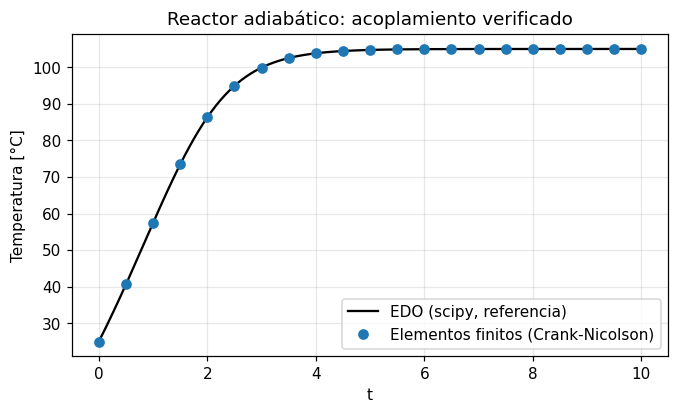

In [26]:
Q_ad, k0_ad, t_end = 400.0, 300.0, 10.0


def adiabatic(theta, dt, n=4):
    mesh_ad = Mesh()
    mesh_ad.generate2DMesh((1.0, 1.0), (n, n), ElementType.quadrilateral)
    mod = Model(name='Adiabatico', dim=2, mesh=mesh_ad, mat=material('Medio', k=k_cond, rho=rho_cp, Cp=1.0), psc=[ht, mt])
    for species in ('A', 'C'):
        mod.physics.mass.setChemSpecies(species, species)
        mod.physics.mass.setDiffusivity(species, D)
    mod.physics.mass.addReaction({'A': -1, 'C': 1}, k0=k0_ad, E_R=E_R, T='T', order={'A': 1}, dH=-Q_ad)
    mod.physics.initField('T', T_amb)
    mod.physics.initField('A', 1.0)
    mod.physics.initField('C', 0.0)
    mod.solverConfiguration(Study=StudyType.transient, Type=ProblemType.nonlinear, Method=SolverType.direct,
                            Solver=DirectSolvers.PARDISO, timeDisc=theta, timeStep=dt, totalTime=t_end)
    solve_quiet(mod)
    return mod


def rhs(t, y):
    r = k0_ad * np.exp(-E_R / (y[0] + 273.15)) * y[1]
    return [Q_ad * r / rho_cp, -r, r]


reference = solve_ivp(rhs, [0, t_end], [T_amb, 1.0, 0.0], method='LSODA', rtol=1e-12, atol=1e-13, dense_output=True)

fem = adiabatic(theta=0.5, dt=0.02)
t_fem = fem.timeVector
T_fem = np.asarray(fem.sol['T'])[0]
T_ode = reference.sol(t_fem)[0]

print(f"T final: elementos finitos {T_fem[-1]:.5f} °C   EDO {T_ode[-1]:.5f} °C")
print(f"Error máximo a lo largo del tiempo: {np.max(np.abs(T_fem - T_ode)):.2e} °C")
print(f"La reacción calentó el reactor adiabático de {T_amb:.0f} a {T_ode[-1]:.1f} °C (Q·A0/rho_cp = {Q_ad / rho_cp:.0f} °C)")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t_fem, T_ode, 'k-', label='EDO (scipy, referencia)')
ax.plot(t_fem[::25], T_fem[::25], 'o', label='Elementos finitos (Crank-Nicolson)')
ax.set_xlabel('t'); ax.set_ylabel('Temperatura [°C]'); ax.set_title('Reactor adiabático: acoplamiento verificado'); ax.legend()
plt.show()

### 12.2 El orden temporal es el teórico

Al reducir el paso de tiempo a la mitad, el error de **Euler implícito** debe reducirse a la mitad (orden 1) y el de
**Crank-Nicolson** a la cuarta parte (orden 2). Se mide contra la misma EDO:

In [27]:
print(f"{'pasos':>6} {'Euler: error':>14} {'orden':>7} {'Crank-N.: error':>17} {'orden':>7}")
previous = {}
for steps in (100, 200, 400):
    row = f"{steps:>6}"
    for theta, label in ((1.0, 'euler'), (0.5, 'cn')):
        mod = adiabatic(theta, t_end / steps)
        error = abs(np.asarray(mod.sol['T'])[0, -1] - reference.sol(t_end)[0])
        order = f"{np.log2(previous[label] / error):.2f}" if label in previous else "-"
        previous[label] = error
        row += f" {error:>14.2e} {order:>7}" if label == 'euler' else f" {error:>17.2e} {order:>7}"
    print(row)

 pasos   Euler: error   orden   Crank-N.: error   orden
   100       1.70e-04       -          3.54e-06       -
   200       7.24e-05    1.23          8.92e-07    1.99
   400       3.34e-05    1.12          2.23e-07    2.00


### 12.3 El jacobiano es consistente

Newton solo converge rápido si el jacobiano es correcto. Se compara el jacobiano analítico (por autodiferenciación) con
**diferencias finitas** sobre una versión pequeña del reactor, en un estado aleatorio. El error debe ser del orden del paso de
diferencias, y los bloques cruzados entre `T` y las especies deben estar presentes:

In [28]:
tiny = build_plate(Q_react, nx=4, ny=2)
tiny_system = tiny._system()

rng = np.random.default_rng(1)
x = np.empty(tiny.layout.ndof)
for name, low, span in (('T', 25.0, 30.0), ('A', 0.2, 0.8), ('C', 0.1, 0.5)):
    x[tiny.layout.dofs(name)[:, 0]] = low + span * rng.random(tiny.mesh.getNoN())

J_exact, R0 = tiny_system.residual_and_tangent(x)
J_exact = J_exact.toarray()
eps = 1e-6
J_fd = np.zeros_like(J_exact)
for j in range(len(x)):
    xp = x.copy()
    xp[j] += eps
    J_fd[:, j] = (tiny_system.residual_and_tangent(xp)[1] - R0) / eps

t_dofs, a_dofs = tiny.layout.dofs('T')[:, 0], tiny.layout.dofs('A')[:, 0]
print(f"Incógnitas: {len(x)}   máx |J analítico - J diferencias finitas| = {np.max(np.abs(J_exact - J_fd)):.2e}")
print(f"Bloque T-A (calor frente a reactivo)       : máx |J| = {np.abs(J_exact[np.ix_(t_dofs, a_dofs)]).max():.3f}")
print(f"Bloque A-T (reacción frente a temperatura) : máx |J| = {np.abs(J_exact[np.ix_(a_dofs, t_dofs)]).max():.3f}")

Incógnitas: 45   máx |J analítico - J diferencias finitas| = 8.20e-08
Bloque T-A (calor frente a reactivo)       : máx |J| = 127.421
Bloque A-T (reacción frente a temperatura) : máx |J| = 0.023


### 12.4 Resumen de la verificación

| Comprobación | Resultado |
|---|---|
| Reactor adiabático frente a una EDO independiente | Coinciden dentro del error temporal |
| Orden temporal | Euler ≈ 1, Crank-Nicolson ≈ 2 |
| Invariante $A + C = 1$ | Exacto a precisión de máquina |
| Balance de energía (generado = paredes + alimentación) | Cierra a precisión de máquina |
| Jacobiano por autodiferenciación frente a diferencias finitas | Coincide, con bloques cruzados presentes |

Estas mismas comprobaciones, y otras, están automatizadas en `Test/test_coupling.py` (`python run_tests.py`).

## 13. Arranque transitorio

Hasta ahora se buscó el estado estacionario. Ahora se simula **cómo llega el reactor a él**, partiendo de la placa fría.
Se cambia la configuración a transitorio:

| Opción | Valor | Significado |
|---|---|---|
| `Study` | `StudyType.transient` | Se calcula la evolución en el tiempo |
| `timeDisc` | `1.0` | $\theta = 1$: **Euler implícito**, robusto y estable (con 0.5 sería Crank-Nicolson, de segundo orden) |
| `timeStep` | `0.02` | Paso de tiempo $\Delta t$ fijo |
| `totalTime` | `1.5` | Tiempo total simulado |

**Qué ocurre en cada paso.** El sistema discreto es $M\,\dot x + R(x) = 0$, con $M$ la matriz de masa. Con el método $\theta$ y
una linealización de Newton al inicio de cada paso se resuelve

$$\left(M + \theta\,\Delta t\,J\right)\Delta x = -\Delta t\,R(x_n)$$

y se avanza $x_{n+1} = x_n + \Delta x$. En un problema lineal la matriz del paso es constante y el solver **reutiliza la factorización**; aquí, con la reacción no lineal,
$J$ cambia en cada paso y se vuelve a factorizar. El resultado se guarda en `model.sol[campo]` con una columna por instante y los tiempos en `model.timeVector`.

75 pasos de tiempo en 2.01 s. La solución tiene forma (861, 76) (nodos × instantes)
T máxima: 25.00 °C (t = 0)  →  42.62 °C (t = 1.5)
Diferencia con el estacionario de la sección 10: 1.62e-02 °C


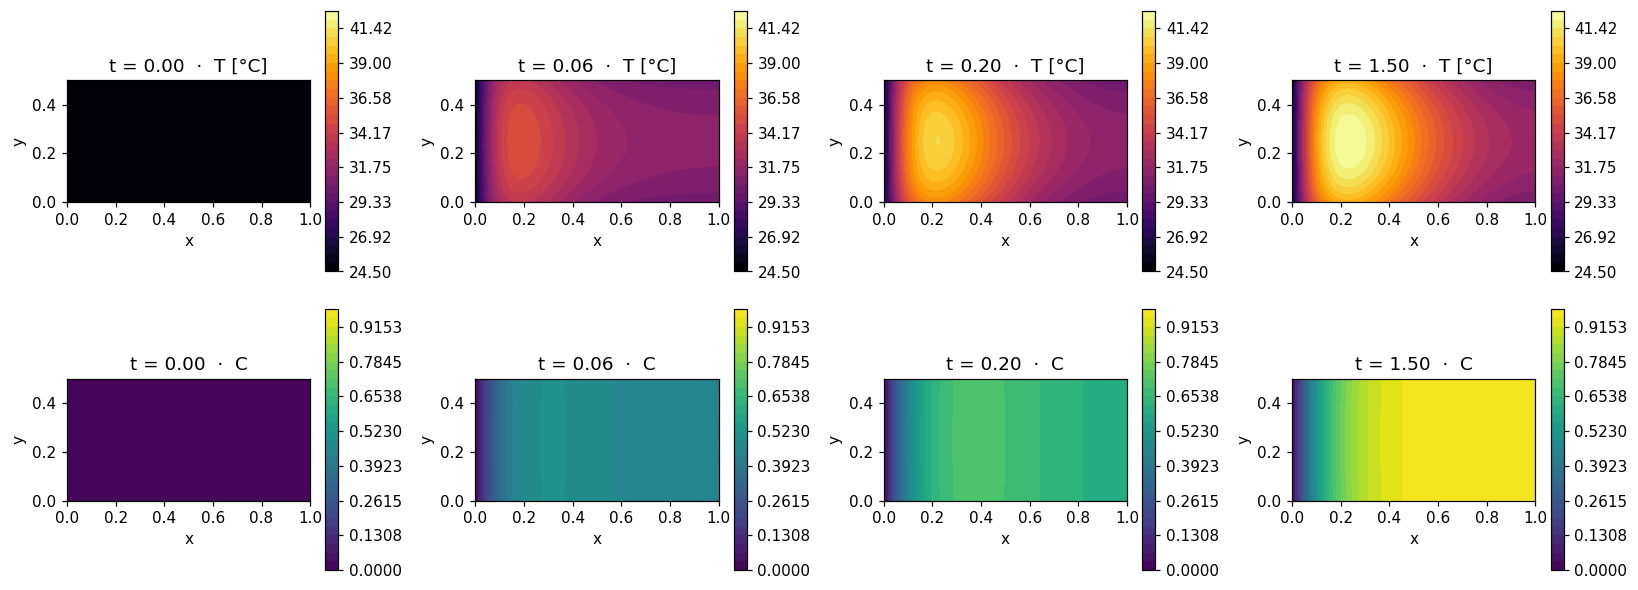

In [29]:
startup = build_plate(Q_react)
startup.solverConfiguration(Study=StudyType.transient, Type=ProblemType.nonlinear, Method=SolverType.direct,
                            Solver=DirectSolvers.PARDISO, timeDisc=1.0, timeStep=0.02, totalTime=1.5)
iterations, converged, elapsed = solve_quiet(startup)

times = startup.timeVector
T_t = np.asarray(startup.sol['T'])
C_t = np.asarray(startup.sol['C'])
print(f"{len(times) - 1} pasos de tiempo en {elapsed:.2f} s. La solución tiene forma {T_t.shape} (nodos × instantes)")
print(f"T máxima: {T_t[:, 0].max():.2f} °C (t = 0)  →  {T_t[:, -1].max():.2f} °C (t = {times[-1]})")
print(f"Diferencia con el estacionario de la sección 10: {np.max(np.abs(T_t[:, -1] - T)):.2e} °C")

snapshots = [0, 3, 10, 75]
T_range = (T_amb - 0.5, T_t.max())          # mismo rango de color en todos los instantes,
C_range = (0.0, C_t.max())                  # para poder compararlos
fig, axes = plt.subplots(2, len(snapshots), figsize=(15, 5.8))
for col, step in enumerate(snapshots):
    plot_field(axes[0, col], startup, T_t[:, step], f't = {times[step]:.2f}  ·  T [°C]', 'inferno', vmin=T_range[0], vmax=T_range[1])
    plot_field(axes[1, col], startup, C_t[:, step], f't = {times[step]:.2f}  ·  C', 'viridis', vmin=C_range[0], vmax=C_range[1])
fig.tight_layout()
plt.show()

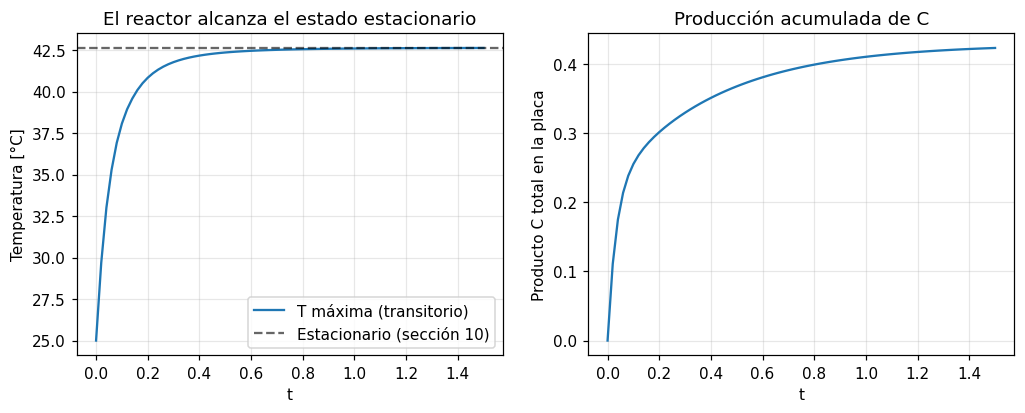

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(times, T_t.max(axis=0), label='T máxima (transitorio)')
ax1.axhline(T.max(), color='k', ls='--', alpha=0.6, label='Estacionario (sección 10)')
ax1.set_xlabel('t'); ax1.set_ylabel('Temperatura [°C]'); ax1.set_title('El reactor alcanza el estado estacionario'); ax1.legend()

total_C = [np.sum(disc.detJw * disc.interpolate(C_t[:, k])) for k in range(len(times))]
ax2.plot(times, total_C)
ax2.set_xlabel('t'); ax2.set_ylabel('Producto C total en la placa'); ax2.set_title('Producción acumulada de C')
plt.show()

**Qué muestra.** La temperatura sube rápido al arrancar la reacción y se **estabiliza** cuando el calor generado iguala al
evacuado. La curva punteada es el estado estacionario de la sección 10: la simulación transitoria lo alcanza, lo que
comprueba que ambos métodos (Newton directo y marcha en el tiempo) dan la misma solución.

## 14. Presentación y resumen

### Qué se hizo

Se resolvió un **reactor exotérmico 2D** en el que la reacción química y la transferencia de calor se influyen mutuamente,
con elementos finitos, en un solo modelo de **tres campos acoplados** ($T$, $A$, $C$).

### Las ideas clave

1. **Una física por clase, un modelo por lista.** `Model(psc=[ht, mt])` combina físicas; cada una se configura por su nombre
   (`heat`, `mass`) y todas comparten malla, campos y sistema.
2. **El acoplamiento es una ley puntual.** La reacción lee $(A, C, T)$ y escribe en las tres ecuaciones; su derivada sale por
   diferenciación automática, así que los bloques cruzados del jacobiano son exactos.
3. **Todo se integra de una vez.** Los operadores calculan las matrices de todos los elementos con álgebra vectorizada;
   la simulación completa (2583 incógnitas) tarda una fracción de segundo.
4. **Newton con residuo escalado.** Cada ecuación se mide en las unidades de su incógnita y la búsqueda de línea mantiene el
   método estable aun con exotermias muy fuertes.
5. **Se verifica con referencias independientes:** una EDO, un invariante exacto, un balance de energía, el orden temporal
   teórico y el jacobiano por diferencias finitas.

### Resultados de este caso

In [31]:
print(f"• Malla de {mesh.getNoE()} elementos Q4 y {mesh.getNoN()} nodos; {layout.ndof} incógnitas (3 campos).")
print(f"• Estado estacionario: T máxima {T.max():.1f} °C sobre un ambiente de {T_amb:.0f} °C; el producto C llega a {C.max():.2f}.")
print(f"• Invariante A + C = 1 exacto: error {np.max(np.abs(A + C - 1.0)):.1e}.")
print(f"• Balance de energía: generado {generated:.4f} = paredes {wall_loss:.4f} + alimentación {feed_loss:.4f}.")
print(f"• Retroalimentación: con Q = 0 la placa queda a {sweep_results[0.0][0]:.0f} °C; con Q = 600, T máxima {sweep_results[600.0][0]:.0f} °C.")
print(f"• Verificación adiabática: error máximo frente a la EDO {np.max(np.abs(T_fem - T_ode)):.1e} °C.")
print(f"• El transitorio converge al estacionario con diferencia {np.max(np.abs(T_t[:, -1] - T)):.1e} °C.")

• Malla de 800 elementos Q4 y 861 nodos; 2583 incógnitas (3 campos).
• Estado estacionario: T máxima 42.6 °C sobre un ambiente de 25 °C; el producto C llega a 1.00.
• Invariante A + C = 1 exacto: error 2.2e-14.
• Balance de energía: generado 265.5372 = paredes 75.0888 + alimentación 190.4485.
• Retroalimentación: con Q = 0 la placa queda a 25 °C; con Q = 600, T máxima 233 °C.
• Verificación adiabática: error máximo frente a la EDO 1.8e-03 °C.
• El transitorio converge al estacionario con diferencia 1.6e-02 °C.


### Cómo seguir

| Quiero... | Dónde mirar |
|---|---|
| Que la difusividad dependa de la temperatura, $D(T)$, o la conductividad de la concentración, $k(c)$ | `System.add_diffusion_law` ya admite varias entradas (`docs/ARQUITECTURA.md`, sección 5.1b) |
| Conductividad dependiente de la temperatura | `heat.setConductivityLaw(lambda T: ...)` (`Test/test_nonlinear_diffusion.py`) |
| Radiación en el borde | `heat.addBC_RadiationEdges(bordes, epsilon, T_ext)` (`Example_2D_Transient.py`) |
| Añadir flujo (convección) | `heat.Convection = True` y `heat.vel`/`mass.vel`; velocidad compartida está pendiente |
| Más reacciones | Llamar varias veces a `mass.addReaction`: se acumulan y se acoplan en una sola ley |
| Entender o ampliar el código | `docs/ARQUITECTURA.md` (capas, convenciones y recetas) y `docs/ESTADO.md` (qué está validado) |
| Ejecutar todas las pruebas | `python run_tests.py` |

> **Límites.** El acoplamiento actual cubre Arrhenius con la temperatura del campo y calor de reacción. Todavía no incluye
> $D(T)$, $k(c)$, $\rho C_p(T)$ ni una velocidad compartida entre calor y especies.